# Exploração SQL e separação temporal

POC DEMO — contrato PROVISÓRIO / PENDENTE DE HOMOLOGAÇÃO. Execute em kernel novo. Credenciais somente por ambiente.


Configuração tipada. Pré-requisitos: Docker saudável, seed DEMO, token por ambiente. Entradas: parâmetros abaixo; saídas: tabelas, IDs e relatório JSON/Markdown. Escritas exigem confirmação EXECUTE_DEMO e chave estável; repetir chave igual recupera o mesmo job. Espere READY; erros de dependência exigem verificar docker compose logs.

In [1]:
import os, json
import pandas as pd
from IPython.display import display, Markdown
from src.workbench.journey_config import Settings
cfg=Settings.load()
from src.workbench.notebook_config import Parameters
from src.workbench.operations_sdk import call, report, await_job
params=Parameters.load()
display(params.model_dump(mode="json"))
display({"state":"READY", "write_enabled":params.execute_write, "tracking":"remote Docker service", "browser_ui":cfg.ui})
evidence={}
NOTEBOOK_ID="03_exploracao_preparacao_dados"


{'mode': 'READ_EXISTING',
 'proposal_id': None,
 'snapshot_id': 'fb931e1e-43d0-5ff8-938c-0d2ba4a68794',
 'model_name': 'hi.demo.notebook.abdb8f09',
 'model_version': '',
 'campaign_id': None,
 'approval_id': None,
 'execute_write': True,
 'confirmation': 'EXECUTE_DEMO',
 'request_key': 'notebooks-abdb8f09',
 'requester': 'scientist-demo',
 'algorithm': 'ridge',
 'alpha': 1.0,
 'capacity': 40,
 'model_count': 30,
 'parallel_jobs': 2,
 'campaign_action': 'observe',
 'governance_action': 'read',
 'review_action': 'APPROVE',
 'reason': '',
 'lineage_kind': 'proposal',
 'external_id': '',
 'reset_mode': 'preview',
 'reinitialize': 'demo-ready',
 'reset_plan_id': None}

{'state': 'READY',
 'write_enabled': True,
 'tracking': 'remote Docker service',
 'browser_ui': 'http://127.0.0.1:5000'}

1. Mostrar SQL versionado, recorte, fonte e qualidade. Esperado: dados sintéticos lidos por conexão SQL fechada pelo módulo.

In [2]:
from src.data.journey import extract,prepare,QUERY,KEYS
frame,snapshot=extract(cfg,snapshot_id=str(params.snapshot_id) if params.snapshot_id else None)
display(Markdown("```sql\n"+QUERY.read_text()+"\n```"));display(snapshot)
display(frame.dtypes.astype(str));display(frame.head(12));display(frame.describe(include="all"))
display(frame.isna().sum());assert not frame.duplicated(KEYS+["semester_index"]).any()
evidence.update(snapshot=snapshot,rows=len(frame),nulls=frame.isna().sum().to_dict())


```sql
-- journey-history-v1. Target: total students per period, replicated to its disciplines
-- under the provisional POC rule: every discipline receives the whole cohort.
SELECT h.course_id::text, h.period_id::text, pd.discipline_id::text,
       h.reference_year * 2 + h.reference_semester - 1 AS semester_index,
       h.reference_semester AS semester,
       h.regular_students + h.dependency_students + h.elective_students AS students
FROM planning.historical_enrollments h
JOIN planning.dataset_snapshots s ON s.id = h.snapshot_id
JOIN planning.academic_cycles c ON c.id = s.cycle_id
JOIN planning.period_disciplines pd ON pd.period_id = h.period_id
WHERE h.snapshot_id = CAST(:snapshot AS uuid) AND c.cycle_code = :cycle
  AND s.sealed_at IS NOT NULL
  AND (CAST(:course AS text) IS NULL OR h.course_id::text = :course)
  AND h.reference_year * 2 + h.reference_semester - 1 < c.target_year * 2 + c.target_semester - 1
ORDER BY semester_index, h.course_id, h.period_id, pd.discipline_id

```

{'id': 'fb931e1e-43d0-5ff8-938c-0d2ba4a68794',
 'snapshot_sha256': '7b4120a14004aeb7cc006c0e210f004a0a6dffd9510bf304f27641b76dbd377e',
 'cycle_id': '0fa6938d-2743-56ae-a057-dffd2274d90a',
 'target_index': 4052,
 'target_semester': 1,
 'dataset_sha256': '5fc39eeeead59aa48813182e6a93d2308a4a9243655501f17d09a981c6c66a56',
 'query_sha256': 'defc10d1b6ea752600af271285c54107663e91db9df13914aea7e42613c83adf',
 'query_version': 'journey-history-v1'}

course_id         object
period_id         object
discipline_id     object
semester_index     int64
semester           int64
students           int64
dtype: object

,course_id,period_id,discipline_id,semester_index,semester,students
0,0169f756-26d1-5ad6-acd4-4e6b0e319939,39c82c86-d06e-5f26-9712-a92b4018084e,172d26b5-b285-5ec4-8971-f3f1cac5befb,4040,1,86
1,0169f756-26d1-5ad6-acd4-4e6b0e319939,39c82c86-d06e-5f26-9712-a92b4018084e,3c7c40f4-7b48-5e65-ad02-fdf7381ae7a3,4040,1,86
2,0169f756-26d1-5ad6-acd4-4e6b0e319939,39c82c86-d06e-5f26-9712-a92b4018084e,5bb84918-2141-55b8-aab6-01257acfa73d,4040,1,86
3,0169f756-26d1-5ad6-acd4-4e6b0e319939,519ead55-4294-52e1-b326-550e4be54cd0,53abed31-c5c0-504e-a7a9-f89f13a31fb3,4040,1,82
4,0169f756-26d1-5ad6-acd4-4e6b0e319939,519ead55-4294-52e1-b326-550e4be54cd0,8098c200-9822-56dc-a701-71f67f356b82,4040,1,82
5,0169f756-26d1-5ad6-acd4-4e6b0e319939,519ead55-4294-52e1-b326-550e4be54cd0,92d8e1a1-d0b5-550f-9bb8-2d5da8257e9e,4040,1,82
6,09786e25-3a0e-5ebe-805c-207a72d98b74,92cbdefd-c378-5e89-b349-680d8e40f22a,688fbec4-cf65-5751-b833-a25d67593022,4040,1,65
7,09786e25-3a0e-5ebe-805c-207a72d98b74,92cbdefd-c378-5e89-b349-680d8e40f22a,c2a826ce-7bb4-53ee-bc6e-b033835ed346,4040,1,65
8,09786e25-3a0e-5ebe-805c-207a72d98b74,92cbdefd-c378-5e89-b349-680d8e40f22a,ffa92517-0737-5806-8b1b-62eab2e7d5ae,4040,1,65
9,09786e25-3a0e-5ebe-805c-207a72d98b74,de0c4144-8a18-5c60-8573-743cb74009ce,1ce60ee2-d495-56bb-8a48-d1c11f65c144,4040,1,81


,course_id,period_id,discipline_id,semester_index,semester,students
count,1050,1050,1050,1050.000000,1050.000000,1050.000000
unique,15,30,90,NaN,NaN,NaN
top,0169f756-26d1-5ad6-acd4-4e6b0e319939,39c82c86-d06e-5f26-9712-a92b4018084e,172d26b5-b285-5ec4-8971-f3f1cac5befb,NaN,NaN,NaN
freq,72,36,12,NaN,NaN,NaN
mean,NaN,NaN,NaN,4045.542857,1.502857,75.894286
std,NaN,NaN,NaN,3.468580,0.500230,13.250943
min,NaN,NaN,NaN,4040.000000,1.000000,41.000000
25%,NaN,NaN,NaN,4043.000000,1.000000,66.000000
50%,NaN,NaN,NaN,4046.000000,2.000000,76.000000
75%,NaN,NaN,NaN,4049.000000,2.000000,86.000000


course_id         0
period_id         0
discipline_id     0
semester_index    0
semester          0
students          0
dtype: int64

2. Evolução e split temporal. Transformações serão ajustadas somente no treino.

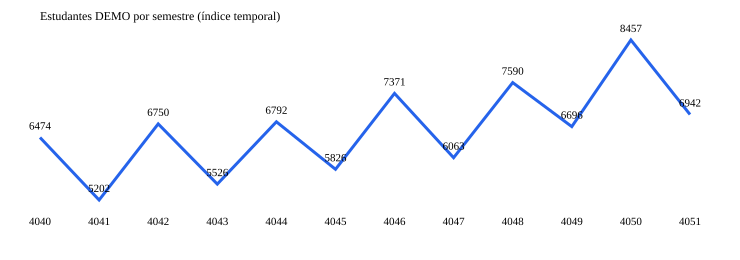

{'train': 960,
 'evaluation': 90,
 'future': 90,
 'train_max': 4050,
 'evaluation_min': 4051,
 'future_min': 4052}

In [3]:
from IPython.display import SVG
from src.workbench.exploration import series_svg
display(SVG(series_svg(frame)))
train,evaluation,future=prepare(frame,snapshot)
split={"train":len(train),"evaluation":len(evaluation),"future":len(future),"train_max":int(train.semester_index.max()),"evaluation_min":int(evaluation.semester_index.min()),"future_min":int(future.semester_index.min())}
display(split);evidence["split"]=split


Guardar evidência desta execução e links. Esperado: caminho do relatório, sem credenciais.

In [4]:
display(report(NOTEBOOK_ID,evidence,limitations=["Dados DEMO e contrato provisório; regras não avaliadas não são homologação"]))


'/reports/v2/03_exploracao_preparacao_dados.json'